# Experiment 3: Data Pre-processing and Cleaning

Change the data in the marked cell, then Runtime -> Run all. Output appears below each cell.

In [1]:
# ------- Step 1: Import required libraries -------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

pd.set_option('display.width', 88)
pd.set_option('display.max_columns', None)

In [2]:
# >>> CHANGE THIS DATA (your own records) and re-run: Runtime -> Run all <<<
# ------- Step 2: Create a messy "real-world" employee dataset -------
data = {
    'EmployeeID': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Name': ['Amit', 'Riya', 'Sam', 'sam', 'Neha', 'Karan', None,
             'Priya', 'Amit', 'Ravi'],
    'Age': [25, 30, np.nan, 28, 45, 200, 32, 27, 25, -5],
    'Department': ['IT', 'hr', 'Finance', 'Finance', 'IT', 'HR', 'IT', None,
                   'IT', 'Finance'],
    'Salary': ['50000', '60000', '55000', '55000', '70000', '65000', 'NaN',
               '58000', '50000', '62000'],
    'JoinDate': ['2020-01-15', '2019-03-22', '2021/07/01', '2021-07-01',
                 '2018-11-30', '2020-06-10', '2022-02-28', '2019-09-14',
                 '2020-01-15', '2021-05-05']
}
df = pd.DataFrame(data)
print("RAW DATASET")
print(df)

RAW DATASET
   EmployeeID   Name    Age Department Salary    JoinDate
0           1   Amit   25.0         IT  50000  2020-01-15
1           2   Riya   30.0         hr  60000  2019-03-22
2           3    Sam    NaN    Finance  55000  2021/07/01
3           4    sam   28.0    Finance  55000  2021-07-01
4           5   Neha   45.0         IT  70000  2018-11-30
5           6  Karan  200.0         HR  65000  2020-06-10
6           7   None   32.0         IT    NaN  2022-02-28
7           8  Priya   27.0       None  58000  2019-09-14
8           9   Amit   25.0         IT  50000  2020-01-15
9          10   Ravi   -5.0    Finance  62000  2021-05-05


In [3]:
# ------- Step 3: Initial data inspection -------
print("\nShape of dataset:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values per column:\n", df.isnull().sum())


Shape of dataset: (10, 6)

Data types:
 EmployeeID      int64
Name           object
Age           float64
Department     object
Salary         object
JoinDate       object
dtype: object

Missing values per column:
 EmployeeID    0
Name          1
Age           1
Department    1
Salary        0
JoinDate      0
dtype: int64


In [4]:
# ------- Step 4: Fix inconsistent text / categories -------
df['Name'] = df['Name'].str.strip().str.title()        # 'sam' -> 'Sam'
df['Department'] = df['Department'].str.strip().str.upper()  # 'hr' -> 'HR'
print("\nDepartments after standardising:",
      df['Department'].dropna().unique().tolist())


Departments after standardising: ['IT', 'HR', 'FINANCE']


In [5]:
# ------- Step 5: Handle missing values -------
df['Name'] = df['Name'].fillna('Unknown')              # placeholder
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Age'] = df['Age'].fillna(df['Age'].median())       # median is robust to outliers
df['Department'] = df['Department'].fillna(
    df['Department'].mode()[0])                        # most frequent value
print("\nMissing values after imputation (Name, Age, Department):")
print(df[['Name', 'Age', 'Department']].isnull().sum())


Missing values after imputation (Name, Age, Department):
Name          0
Age           0
Department    0
dtype: int64


In [6]:
# ------- Step 6: Remove duplicate records -------
print("\nExact duplicate rows:", df.duplicated().sum(),
      "(EmployeeID is unique, so we check Name + Age)")
dups = df[df.duplicated(subset=['Name', 'Age'], keep=False)]
print("Records sharing the same Name and Age:")
print(dups)
df = df.drop_duplicates(subset=['Name', 'Age'], keep='first')
print("Rows remaining:", len(df))


Exact duplicate rows: 0 (EmployeeID is unique, so we check Name + Age)
Records sharing the same Name and Age:
   EmployeeID  Name   Age Department Salary    JoinDate
0           1  Amit  25.0         IT  50000  2020-01-15
2           3   Sam  28.0    FINANCE  55000  2021/07/01
3           4   Sam  28.0    FINANCE  55000  2021-07-01
8           9  Amit  25.0         IT  50000  2020-01-15
Rows remaining: 8


In [7]:
# ------- Step 7: Fix data-type issues -------
df['Salary'] = df['Salary'].replace('NaN', np.nan)     # text 'NaN' -> real missing value
df['Salary'] = pd.to_numeric(df['Salary'], errors='coerce')  # text -> number
df['Salary'] = df['Salary'].fillna(df['Salary'].median())
df['JoinDate'] = df['JoinDate'].str.replace('/', '-')  # unify date separators
df['JoinDate'] = pd.to_datetime(df['JoinDate'], format='%Y-%m-%d')
print("\nData types after conversion:\n", df.dtypes)


Data types after conversion:
 EmployeeID             int64
Name                  object
Age                  float64
Department            object
Salary               float64
JoinDate      datetime64[ns]
dtype: object



Unrealistic ages replaced with median of valid ages = 29.0
      Name   Age
0     Amit  25.0
1     Riya  30.0
2      Sam  28.0
4     Neha  45.0
5    Karan  29.0
6  Unknown  32.0
7    Priya  27.0
9     Ravi  29.0


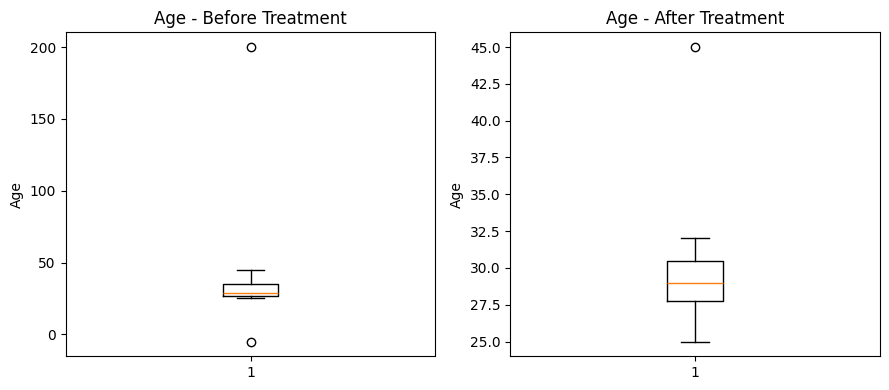


Salary IQR: Q1 = 57250, Q3 = 62750, IQR = 5500
Bounds: [49000, 71000]
Salary outliers detected: 0


In [8]:
# ------- Step 8: Outlier detection and treatment -------
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
axs[0].boxplot(df['Age'])
axs[0].set_title("Age - Before Treatment")
axs[0].set_ylabel("Age")

# Treat unrealistic ages (< 0 or > 100) with the median of the valid ages
valid = df['Age'].between(0, 100)
median_valid = df.loc[valid, 'Age'].median()
df.loc[~valid, 'Age'] = median_valid
print("\nUnrealistic ages replaced with median of valid ages =", median_valid)
print(df[['Name', 'Age']])

axs[1].boxplot(df['Age'])
axs[1].set_title("Age - After Treatment")
axs[1].set_ylabel("Age")
plt.tight_layout()
plt.show()

# Alternative: IQR method on Salary
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['Salary'] < lower_bound) | (df['Salary'] > upper_bound)]
print("\nSalary IQR: Q1 = %.0f, Q3 = %.0f, IQR = %.0f" % (Q1, Q3, IQR))
print("Bounds: [%.0f, %.0f]" % (lower_bound, upper_bound))
print("Salary outliers detected:", len(outliers))

In [9]:
# ------- Step 9: Encode categorical variables -------
le = LabelEncoder()
df['Department_Encoded'] = le.fit_transform(df['Department'])
print("\nLabel encoding classes:", {c: int(i) for i, c in enumerate(le.classes_)})
df_encoded = pd.get_dummies(df, columns=['Department'], prefix='Dept', dtype=int)
print(df_encoded.head())


Label encoding classes: {'FINANCE': 0, 'HR': 1, 'IT': 2}
   EmployeeID   Name   Age   Salary   JoinDate  Department_Encoded  Dept_FINANCE  \
0           1   Amit  25.0  50000.0 2020-01-15                   2             0   
1           2   Riya  30.0  60000.0 2019-03-22                   1             0   
2           3    Sam  28.0  55000.0 2021-07-01                   0             1   
4           5   Neha  45.0  70000.0 2018-11-30                   2             0   
5           6  Karan  29.0  65000.0 2020-06-10                   1             0   

   Dept_HR  Dept_IT  
0        0        1  
1        1        0  
2        0        0  
4        0        1  
5        1        0  


In [10]:
# ------- Step 10: Feature scaling -------
scaler = StandardScaler()      # mean = 0, std = 1
df['Salary_Standardized'] = scaler.fit_transform(df[['Salary']])
minmax = MinMaxScaler()        # range 0 to 1
df['Age_Normalized'] = minmax.fit_transform(df[['Age']])
print("\nScaled columns:")
print(df[['Salary', 'Salary_Standardized', 'Age', 'Age_Normalized']].round(4))


Scaled columns:
    Salary  Salary_Standardized   Age  Age_Normalized
0  50000.0              -1.7609  25.0            0.00
1  60000.0               0.0000  30.0            0.25
2  55000.0              -0.8805  28.0            0.15
4  70000.0               1.7609  45.0            1.00
5  65000.0               0.8805  29.0            0.20
6  60000.0               0.0000  32.0            0.35
7  58000.0              -0.3522  27.0            0.10
9  62000.0               0.3522  29.0            0.20


In [11]:
# ------- Step 11: Final cleaned dataset -------
print("\nFinal cleaned dataset:")
print(df)
print("\nFinal shape:", df.shape)
print("\nRemaining missing values:\n", df.isnull().sum())


Final cleaned dataset:
   EmployeeID     Name   Age Department   Salary   JoinDate  Department_Encoded  \
0           1     Amit  25.0         IT  50000.0 2020-01-15                   2   
1           2     Riya  30.0         HR  60000.0 2019-03-22                   1   
2           3      Sam  28.0    FINANCE  55000.0 2021-07-01                   0   
4           5     Neha  45.0         IT  70000.0 2018-11-30                   2   
5           6    Karan  29.0         HR  65000.0 2020-06-10                   1   
6           7  Unknown  32.0         IT  60000.0 2022-02-28                   2   
7           8    Priya  27.0         IT  58000.0 2019-09-14                   2   
9          10     Ravi  29.0    FINANCE  62000.0 2021-05-05                   0   

   Salary_Standardized  Age_Normalized  
0            -1.760902            0.00  
1             0.000000            0.25  
2            -0.880451            0.15  
4             1.760902            1.00  
5             0.880451 